In [2]:
#1. Significant earthquakes since 2150 B.C.
import numpy as np
import pandas as pd
import xarray as xr
import netCDF4
from matplotlib import pyplot as plt
%matplotlib inline

Sig_Eqs = pd.read_csv(r"D:\ESE5023\earthquakes-2026-10-14_21-39-07_+0800.tsv", sep='\t')
Sig_Eqs.sort_values("Country")

,Search Parameters,Id,Year,Mo,Dy,Hr,Mn,Sec,Tsu,Vol,...,Total Missing,Total Missing Description,Total Injuries,Total Injuries Description,Total Damage ($Mil),Total Damage Description,Total Houses Destroyed,Total Houses Destroyed Description,Total Houses Damaged,Total Houses Damaged Description
60,NaN,46.0,50.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN
222,NaN,202.0,818.0,5.0,15.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN
349,NaN,379.0,1102.0,2.0,28.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
633,NaN,667.0,1505.0,7.0,6.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,3.0,NaN,3.0,NaN,NaN
1728,NaN,1751.0,1832.0,1.0,22.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3558,NaN,8182.0,1941.0,1.0,11.0,8.0,32.0,59.0,NaN,NaN,...,NaN,NaN,200.0,3.0,NaN,NaN,700.0,3.0,1000.0,3.0
4646,NaN,4954.0,1982.0,12.0,13.0,9.0,12.0,48.0,NaN,NaN,...,NaN,NaN,1500.0,4.0,2000.0,4.0,NaN,4.0,NaN,NaN
4979,NaN,5312.0,1991.0,11.0,22.0,0.0,40.0,23.9,NaN,NaN,...,NaN,NaN,40.0,1.0,NaN,2.0,17.0,1.0,87.0,2.0
6237,NaN,10404.0,2017.0,2.0,24.0,0.0,32.0,17.8,NaN,NaN,...,NaN,NaN,5.0,1.0,NaN,1.0,NaN,1.0,NaN,NaN


In [15]:
Sig_Eqs.info()

<class 'pandas.DataFrame'>
RangeIndex: 6698 entries, 0 to 6697
Data columns (total 49 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Search Parameters                   1 non-null      str    
 1   Id                                  6697 non-null   float64
 2   Year                                6697 non-null   float64
 3   Mo                                  6293 non-null   float64
 4   Dy                                  6122 non-null   float64
 5   Hr                                  4580 non-null   float64
 6   Mn                                  4357 non-null   float64
 7   Sec                                 3864 non-null   float64
 8   Tsu                                 2124 non-null   float64
 9   Vol                                 82 non-null     float64
 10  Country                             6697 non-null   str    
 11  Area                                335 non-null    st

In [27]:
#1.1
need1_1 = Sig_Eqs.groupby('Country')['Deaths'].sum()   #计算自公元前2150年以来每个国家因地震而死亡的总人数
need1_1 = need1.sort_values(ascending=False)           #将表格按总死亡人数排序
need1_1.head(20)                                       #打印前20个国家以及死亡总数

Country
CHINA           2139209.0
TURKEY          1199720.0
IRAN            1014453.0
ITALY            492236.0
SYRIA            419826.0
HAITI            323484.0
AZERBAIJAN       319251.0
JAPAN            242516.0
ARMENIA          177890.0
PAKISTAN         145085.0
IRAQ             136200.0
ECUADOR          135496.0
TURKMENISTAN     117412.0
PERU             102309.0
ISRAEL            93388.0
PORTUGAL          83572.0
GREECE            81162.0
CHILE             64277.0
INDIA             63507.0
TAIWAN            57154.0
Name: Deaths, dtype: float64

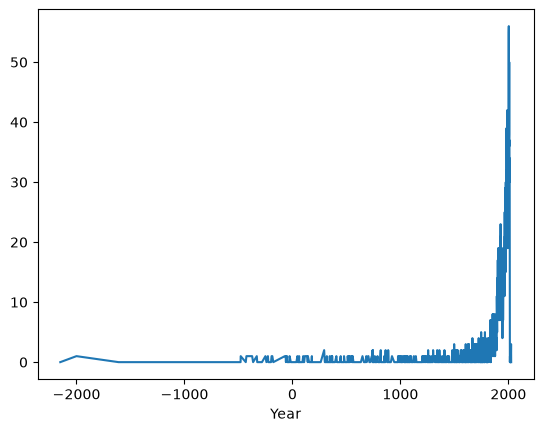

In [32]:
#1.2
need1_2 = (Sig_Eqs['Ms'] > 3.0).groupby(Sig_Eqs['Year']).sum().plot()#先找到Ms值大于3.0的所有行，然后将这些行按年份分组并求和，最后画图展示
plt.show()

In [44]:
#1.3
def CountEq_LargestEq(c):         
    need1_3 = Sig_Eqs.groupby('Country').get_group(c)#先按国家分组并得到一个新的表格
    a = len(need1_3)
    if need1_3['Ms'].isna().all():#若该国 Ms 全为空白，则无法找最大值，返回空值
        b = 'N/A, N/A'
        return a,b
    max_ms = need1_3.loc[need1_3['Ms'].idxmax()]
    if pd.isna(max_ms['Year']) or pd.isna(max_ms['Mo']) or pd.isna(max_ms['Dy']):#提取日期，若为空白则填入N/A
        max_date = 'N/A'
    else:
        max_date = f"{int(max_ms['Year'])}/{int(max_ms['Mo'])}/{int(max_ms['Dy'])}"
    max_location = max_ms['Location Name']
    b = f"{max_date}, {max_location}"
    return a,b

countries = Sig_Eqs['Country'].dropna().unique()#找到所有国家，保证只出现一次且去除空白国家
results = []

for c in countries:
    total, largest = CountEq_LargestEq(c)
    results.append({
        'Country': c,
        'TotalEq': total,
        'LargestEq': largest
    })
    
results_df = pd.DataFrame(results).sort_values('TotalEq', ascending=False)

print(results_df.to_string(index=False))

                                     Country  TotalEq                                                       LargestEq
                                       CHINA      626             1920/12/16, CHINA:  GANSU PROVINCE, SHANXI PROVINCE
                                       JAPAN      429                                       869/7/13, JAPAN:  SANRIKU
                                   INDONESIA      427         2004/12/26, INDONESIA:  SUMATRA:  ACEH:  OFF WEST COAST
                                        IRAN      385                                856/12/22, IRAN:  DAMGHAN, QUMIS
                                      TURKEY      359                                   1939/12/26, TURKEY:  ERZINCAN
                                       ITALY      338                   1915/1/13, ITALY:  MARSICA, AVEZZANO, ABRUZZI
                                      GREECE      296                              365/7/21, GREECE:  CRETE:  KNOSSOS
                                         USA      283   

C:\Users\86133\AppData\Local\Temp\ipykernel_44900\2086897231.py:2: DtypeWarning: Columns (0: CALL_SIGN, 1: AA3, 2: AG1, 3: AJ1, 4: AW1, 5: AZ1, 6: CALL_SIGN.1, 7: GA5, 8: GE1, 9: HL1, 10: IA2, 11: KA2, 12: ME1, 13: MW3, 14: OA1, 15: OD1, 16: OD2, 17: SA1, 18: UA1, 19: UG1) have mixed types. Specify dtype option on import or set low_memory=False.
  weather = pd.read_csv(r"D:\ESE5023\Baoan_Weather_1998_2022.csv")


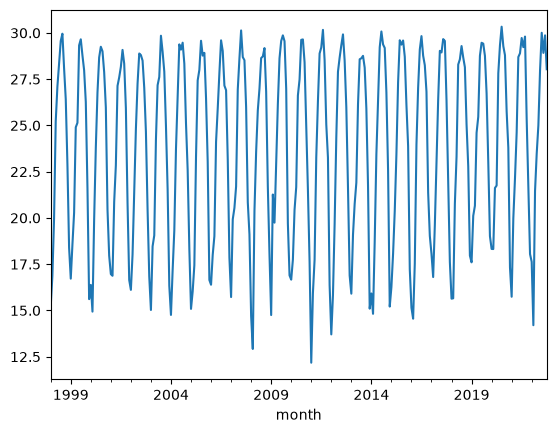

In [56]:
#2
weather = pd.read_csv(r"D:\ESE5023\Baoan_Weather_1998_2022.csv")
#weather.info()
weather["DATE"] = pd.to_datetime(weather["DATE"], format="%Y-%m-%dT%H:%M:%S", errors="coerce")#识别日期
weather["month"] = weather["DATE"].dt.to_period("M")

t = weather["TMP"].astype("string").str.strip()#将TMP列的所有值转为字符串并识别是否为无效值，同时去除后缀
t = t.str.split(",").str[0].str.strip()
nan = t.isin(["+9999"])
weather = weather.loc[~nan].copy()#生成没有无效值的表格

weather["TMP"] = pd.to_numeric(t.loc[~nan]) / 10.0#转会数值并除以缩放因子变成实际值

weather.groupby("month")["TMP"].mean().sort_index().plot()
plt.show()

In [3]:
#3
df = pd.read_csv(r"D:\ESE5023\ibtracs.ALL.list.v04r00.csv",
                 usecols=range(17),#只读取前 17 列
                 skiprows=[1, 2], #跳过文件中的第 2、3 行
                 parse_dates=['ISO_TIME'],#把 ISO_TIME 列解析成 datetime，后续可以直接 .dt.year等
                 na_values=['NOT_NAMED', 'NAME'])#指定哪些字符串视为缺失值
df.head()

C:\Users\86133\AppData\Local\Temp\ipykernel_9344\1663667719.py:2: DtypeWarning: Columns (0: NAME) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(r"D:\ESE5023\ibtracs.ALL.list.v04r00.csv",


,SID,SEASON,NUMBER,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,LON,WMO_WIND,WMO_PRES,WMO_AGENCY,TRACK_TYPE,DIST2LAND,LANDFALL,IFLAG
0,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 06:00:00,NR,10.8709,79.8265,,,,main,0,0,__________P___
1,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 09:00:00,NR,10.8431,79.3524,,,,main,0,0,__________P___
2,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 12:00:00,NR,10.8188,78.8772,,,,main,0,0,__________P___
3,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 15:00:00,NR,10.8000,78.4000,,,,main,0,0,__________O___
4,1842298N11080,1842,1,NI,AS,NaN,1842-10-25 18:00:00,NR,10.7884,77.9194,,,,main,0,0,__________P___


In [8]:
#3.1
need3_1 = df.groupby('SID').agg(NAME=('NAME', 'first'),WMO_WIND=('WMO_WIND', 'max')).sort_values('WMO_WIND', ascending=False).head(10)
need3_1['NAME']

SID
1886225N13320    NaN
1886226N15336    NaN
1886277N14279    NaN
1887226N14328    NaN
1887226N16302    NaN
1888228N23289    NaN
1888239N13328    NaN
1888283N22267    NaN
1889255N16301    NaN
1890237N13311    NaN
Name: NAME, dtype: str

In [9]:
#3.2
need3_2 = (df.groupby('SID')['WMO_WIND'].max().sort_values(ascending=False).head(20))
need3_2

SID
1886225N13320    95
1886226N15336    95
1886277N14279    95
1887226N14328    95
1887226N16302    95
1888228N23289    95
1888239N13328    95
1888283N22267    95
1889255N16301    95
1890237N13311    95
1891229N11313    95
1893225N12331    95
1893226N10310    95
1893228N18340    95
1893268N12335    95
1893271N16278    95
1894242N13325    95
1894261N13311    95
1894270N12284    95
1894284N11303    95
Name: WMO_WIND, dtype: str

In [12]:
#3.3
need3_3 = df.groupby('BASIN').size().sort_values(ascending=False)#先按流域分组，然后求各自数据点总数量，最后排序
need3_3

BASIN
WP    236576
SI    160668
SP     67119
EP     62412
NI     55401
SA       119
dtype: int64

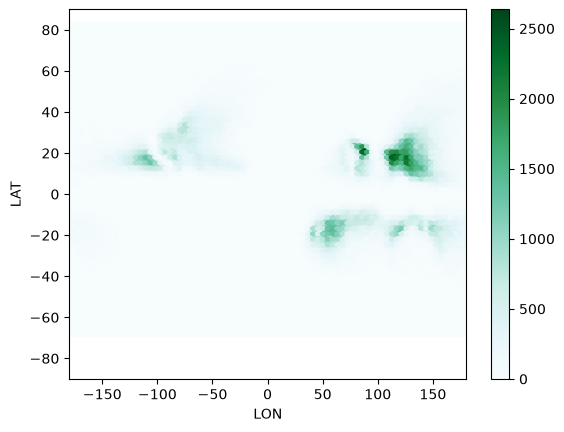

In [15]:
#3.4
df.plot.hexbin(x='LON', y='LAT',)
plt.xlim(-180, 180)#限制xy的作图范围
plt.ylim(-90, 90)
plt.show()

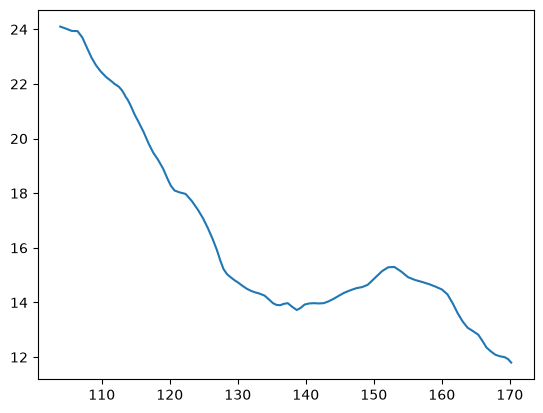

In [17]:
#3.5
need3_5 = df.loc[(df['NAME'] == 'MANGKHUT') & (df['SEASON'] == 2018)].sort_values('ISO_TIME')#先按名字和时间定位找到目标台风
plt.plot(need3_5['LON'], need3_5['LAT'])
plt.show()

In [18]:
#3.6
df2 = df.loc[(df['SEASON'] >= 1970) & (df['BASIN'].isin(['WP', 'EP']))].copy()
df2.head()

,SID,SEASON,NUMBER,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,LON,WMO_WIND,WMO_PRES,WMO_AGENCY,TRACK_TYPE,DIST2LAND,LANDFALL,IFLAG
350393,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 00:00:00,TS,7.00000,151.400,,1006,tokyo,main,1088,1088,_OO___________
350394,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 03:00:00,TS,7.24752,151.205,,,,main,1109,1109,_PP___________
350395,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 06:00:00,TS,7.50000,151.000,,1002,tokyo,main,1143,1143,_OO___________
350396,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 09:00:00,TS,7.75747,150.772,,,,main,1171,1168,_PP___________
350397,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 12:00:00,TS,8.00000,150.500,,998,tokyo,main,1182,1179,_OO___________


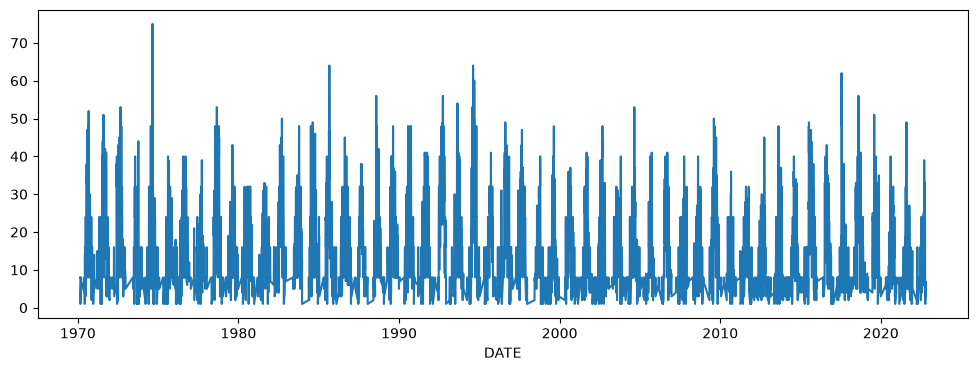

In [26]:
#3.7
need3_7 = df2.assign(DATE=df2['ISO_TIME'].dt.date).groupby('DATE').size().sort_index().plot(figsize=(12, 4))

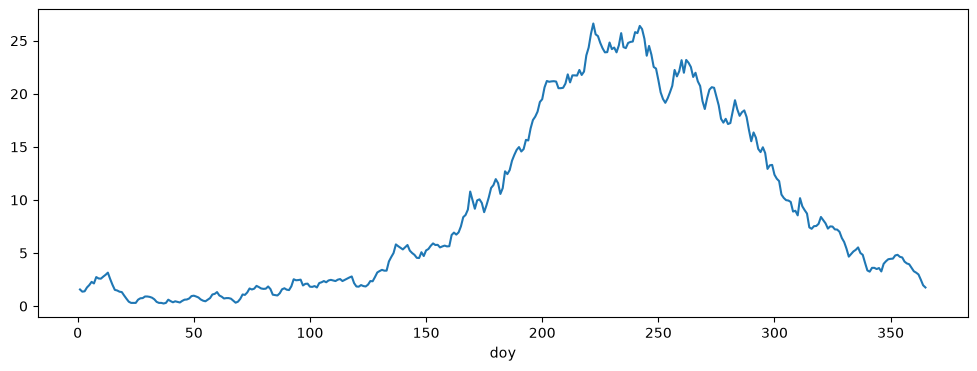

In [25]:
#3.8排除了闰年影响
doy = df2['ISO_TIME'].dt.dayofyear.rename('doy')
yr  = df2['ISO_TIME'].dt.year.rename('year')
need3_8 = df2.groupby([yr, doy]).size().unstack(fill_value=0)

clim = need3_8.loc[:, need3_8.columns <= 365].mean(axis=0).sort_index()

clim.plot(figsize=(12, 4))#拉长画布
plt.show()

In [24]:
#3.9
daily = daily.assign(clim=daily['doy'].map(clim))
daily['anomaly'] = daily['count'] - daily['clim']
daily.head()

,year,doy,count,clim,anomaly
0,1970,50,8,6.500000,1.500000
1,1970,51,8,8.000000,0.000000
2,1970,52,8,7.166667,0.833333
3,1970,53,8,6.600000,1.400000
4,1970,54,8,5.400000,2.600000


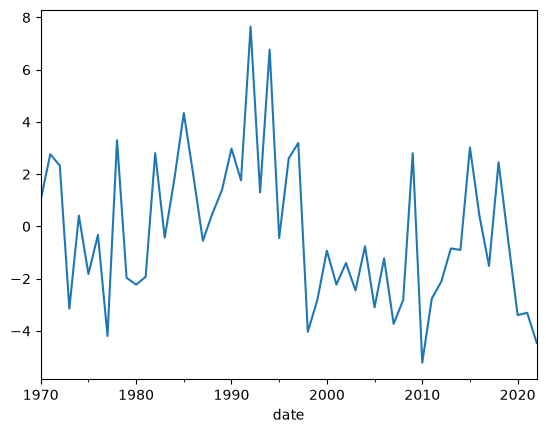

正异常最大的年份（飓风偏活跃）：
date
1992-12-31    7.645086
1994-12-31    6.769985
1985-12-31    4.338109
1978-12-31    3.298956
1997-12-31    3.195031
Name: anomaly, dtype: float64

负异常最大的年份（飓风偏不活跃）：
date
2010-12-31   -5.217217
2022-12-31   -4.456293
1977-12-31   -4.192921
1998-12-31   -4.035779
2007-12-31   -3.731739
Name: anomaly, dtype: float64


In [36]:
#3.10
daily['date'] = (
    pd.to_datetime(daily['year'].astype(str) + '-01-01')
    + pd.to_timedelta(daily['doy'].astype(int) - 1, unit='D')
)

# 把 date 设为索引，取 anomaly 列
anomaly1 = daily.set_index('date')['anomaly']

# 按年重采样取年平均异常
year_anomaly = anomaly1.resample('YE').mean()

year_anomaly.plot()
plt.show()

# 排序识别最异常的年份
print("正异常最大的年份（飓风偏活跃）：")
print(year_anomaly.sort_values(ascending=False).head(5))
print("\n负异常最大的年份（飓风偏不活跃）：")
print(year_anomaly.sort_values().head(5))

In [31]:
#4
gz = pd.read_excel(r"D:\ESE5023\592870-2024-bj.xlsx")
gz.head()
print(gz.shape)
print(gz.dtypes)
print(gz.head())
print(gz.columns.tolist())

(8420, 9)
年                   int64
月                   int64
日                   int64
小时                  int64
气温（*10）             int64
风向                  int64
风速（ *10，m/s）        int64
降水量（一小时时段*10,mm）    int64
降水量（六小时时段*10,mm）    int64
dtype: object
      年  月  日  小时  气温（*10）    风向  风速（ *10，m/s）  降水量（一小时时段*10,mm）  \
0  2024  1  1   0      200    80            20             -9999   
1  2024  1  1   1      200    50            20             -9999   
2  2024  1  1   2      169   350            10             -9999   
3  2024  1  1   3      200    60            30             -9999   
4  2024  1  1   4      190 -9999            10             -9999   

   降水量（六小时时段*10,mm）  
0             -9999  
1             -9999  
2                 0  
3             -9999  
4             -9999  
['年', '月', '日', '小时', '气温（*10）', '风向', '风速（ *10，m/s）', '降水量（一小时时段*10,mm）', '降水量（六小时时段*10,mm）']


In [32]:
#4.1
t_gz = '气温（*10）'
gz = gz.loc[gz[t_gz] != -9999].copy()

D:\tool\Anacanda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


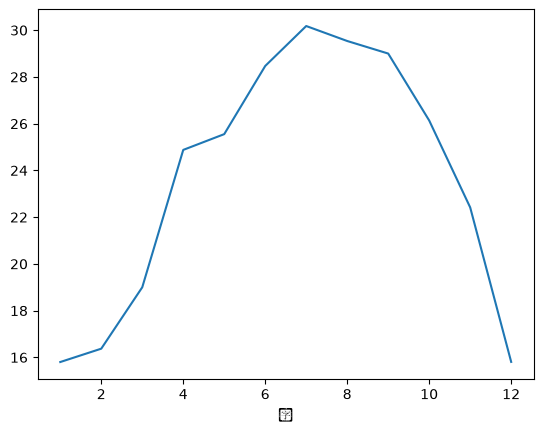

In [33]:
#4.2
gz['TEMP'] = gz[t_gz] / 10.0#除以缩放因子变成实际值

gz.groupby('月')['TEMP'].mean().sort_index().plot()
plt.show()

In [35]:
4.3
last = {
    'mean':     gz['TEMP'].mean(),
    'median':   gz['TEMP'].median(),
    'var':      gz['TEMP'].var(),        # 方差
    'std':      gz['TEMP'].std(),
    'skew':     gz['TEMP'].skew(),       # 偏度
    'IQR':      gz['TEMP'].quantile(0.75) - gz['TEMP'].quantile(0.25),
}
print(pd.Series(last).round(2))

mean      23.67
median    25.00
var       45.77
std        6.77
skew      -0.61
IQR        8.00
dtype: float64
